In [10]:
import numpy as np
import trimesh as tm
import torch
import open3d as o3d

import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


In [2]:
path = './PPtac.stl'
mesh = tm.load(path)


In [3]:
mesh.show()

In [4]:
def visualize_point_cloud_matplotlib(points, color='b', size=1):
    """
    使用matplotlib可视化点云
    points: torch.Tensor of shape (N, 3)
    """
    if isinstance(points, torch.Tensor):
        points = points.cpu().numpy()
    
    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection='3d')
    
    ax.scatter(points[:, 0], points[:, 1], points[:, 2], 
               c=color, s=size, alpha=0.6)
    
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('Z')
    plt.show()


In [5]:
pts = mesh.sample(20000, return_index=False)

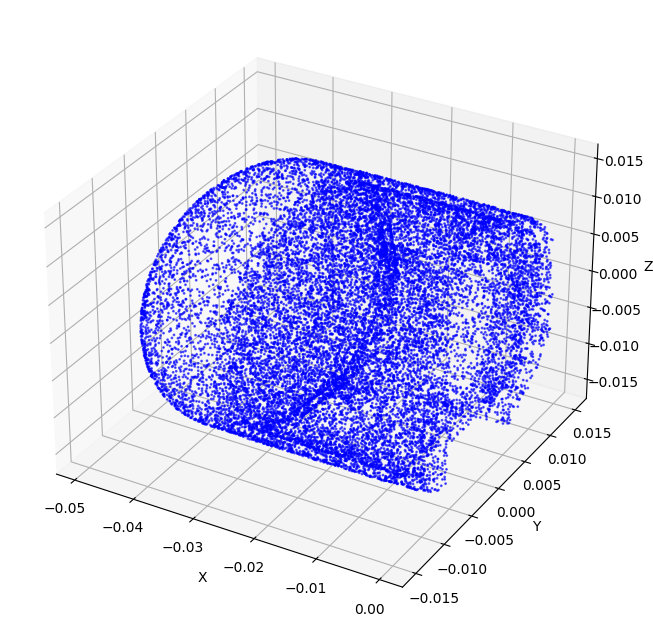

In [6]:
visualize_point_cloud_matplotlib(pts)

In [7]:
def visualize_point_cloud_open3d(points, colors=None):
    """
    使用Open3D可视化点云
    """
    if isinstance(points, torch.Tensor):
        points = points.cpu().numpy()
    
    # 创建Open3D点云对象
    pcd = o3d.geometry.PointCloud()
    pcd.points = o3d.utility.Vector3dVector(points)
    
    # 设置颜色（可选）
    if colors is not None:
        if isinstance(colors, torch.Tensor):
            colors = colors.cpu().numpy()
        pcd.colors = o3d.utility.Vector3dVector(colors)
    else:
        # 随机颜色或基于坐标的颜色
        colors = np.random.uniform(0, 1, size=(len(points), 3))
        pcd.colors = o3d.utility.Vector3dVector(colors)
    
    # 创建坐标轴（长度可调）
    coordinate_frame = o3d.geometry.TriangleMesh.create_coordinate_frame(
        size=0.03,  # 坐标轴长度
        origin=[0, 0, 0]  # 坐标原点
    )
    
    # 在notebook中显示
    o3d.visualization.draw_geometries([pcd, coordinate_frame])

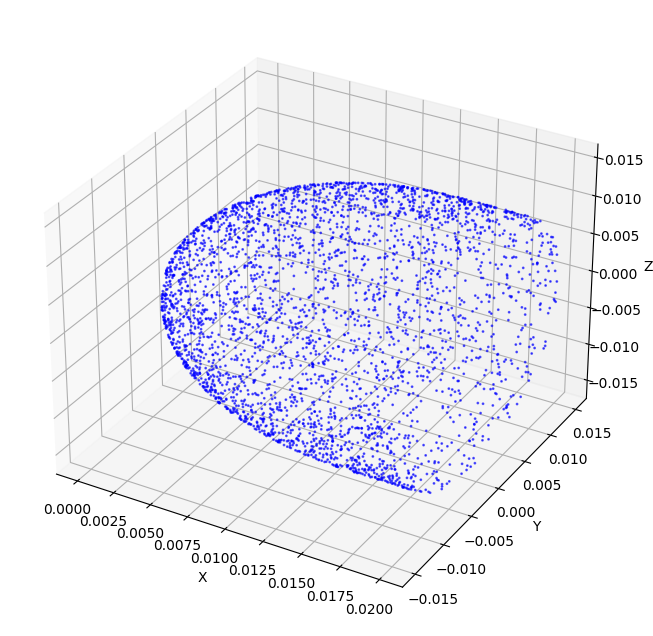

In [8]:
pts_tensor = torch.tensor(pts)
pts_tensor[:, 0] -= torch.min(pts_tensor[:, 0])
mask = pts_tensor[:, 0]<0.02
pts1 = pts_tensor[mask]

visualize_point_cloud_matplotlib(pts1)

In [11]:
visualize_point_cloud_open3d(pts1)